<a href="https://colab.research.google.com/github/felipefe/python-version/blob/main/k_means_clusters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#não supervisionado

from sklearn import datasets
from sklearn.metrics import confusion_matrix
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

In [ ]:
iris = datasets.load_iris()
iris

In [12]:
def plot_clusters(data, labels, title):
  colors = ["red", "green", "blue", "black"]
  plt.figure(figsize=(8, 4))
  for i, c, l in zip(range(-1, 3), colors, ['Noise', 'Setosa', 'Versicolor', 'Virginica']):
    if (i == -1):
      plt.scatter(data[labels == i, 0], data[labels == i, 3], c=colors[i], label=l, alpha=0.7, s=50, marker='x')
    else:
      plt.scatter(data[labels == i, 0], data[labels == i, 3], c=colors[i], label=l, alpha=0.7, s=50)
  plt.legend()
  plt.title(title)
  plt.xlabel('Petal length')
  plt.ylabel('Petal width')
  plt.show()

In [3]:
kmeans = KMeans(n_clusters=3, n_init="auto")
kmeans.fit(iris.data)
print(kmeans.labels_)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


[[ 0 50  0]
 [47  0  3]
 [14  0 36]]


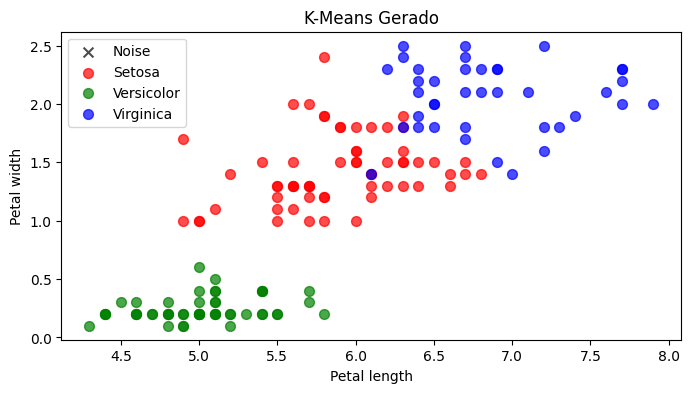

In [13]:
result = confusion_matrix(iris.target, kmeans.labels_)
print(result)

plot_clusters(iris.data, kmeans.labels_, 'K-Means Gerado')

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  2  1  1  2  1  1  1  1  1  1  1 -1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  2  1  1
  1  1  2  1  1  1  1  1  1  3 -1  1 -1 -1  1  1  1  1  1  1  1 -1  3  1
  1  1  3  1  1  1  1  1  1  1  1 -1  1  1 -1 -1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]


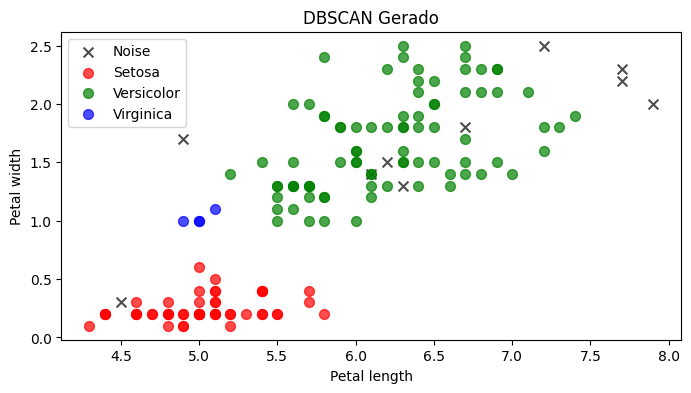

In [14]:
scan = DBSCAN(eps=0.5, min_samples=3)
scan.labels_ = scan.fit_predict(iris.data)
print(scan.labels_)

plot_clusters(iris.data, scan.labels_, 'DBSCAN Gerado')

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[[ 0 50  0]
 [49  0  1]
 [15  0 35]]


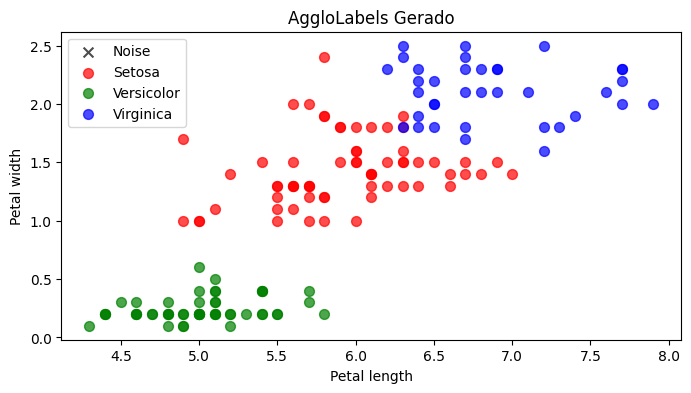

In [15]:
agglo = AgglomerativeClustering(n_clusters=3)
agglo.fit_predict(iris.data)
print(agglo.labels_)

result = confusion_matrix(iris.target, agglo.labels_)
print(result)

plot_clusters(iris.data, agglo.labels_, 'AggloLabels Gerado')

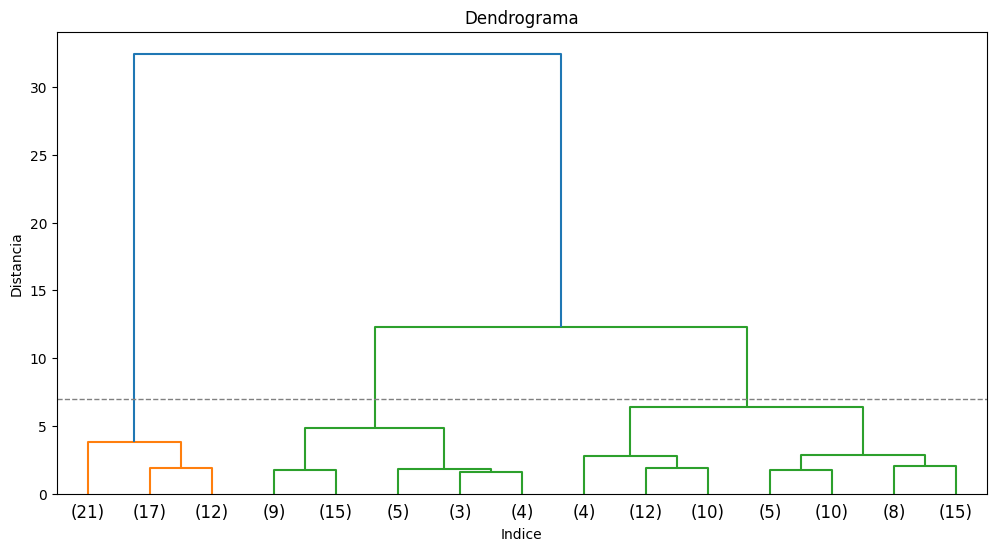

In [18]:
plt.figure(figsize=(12, 6))
plt.title('Dendrograma')
plt.xlabel('Indice')
plt.ylabel('Distancia')
dendrogram(linkage(iris.data, method='ward'), truncate_mode='lastp', p=15)
plt.axhline(y=7, c='gray', lw=1, ls='dashed')
plt.show()